In [8]:
from chemprop_utils import load_and_clean_data, build_splits, build_and_train_mpnn, predict_test_set
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle
from pathlib import Path
from rdkit import Chem
from rdkit.Chem import Descriptors

#LOAD THE LOCKED BASELINE'S SPLIT + PREDICTIONS FROM 03 (POST-HOC ANALYSIS — NO RETRAINING NEEDED FOR PART 1)
with open("dHfus_baseline_splits.pkl", "rb") as f:
    splits = pickle.load(f)
baseline_predictions = pd.read_csv("dHfus_baseline_predictions.csv")

#COMPUTE MOLECULAR WEIGHT FOR EACH TEST-SET MOLECULE, USING THE SMILES ALREADY SAVED IN baseline_predictions
baseline_predictions["MW"] = baseline_predictions["smiles"].apply(
    lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s))
)
print(baseline_predictions["MW"].describe())


count     465.000000
mean      274.050299
std       113.097233
min        80.090000
25%       196.290000
50%       260.333000
75%       317.319000
max      1136.067000
Name: MW, dtype: float64


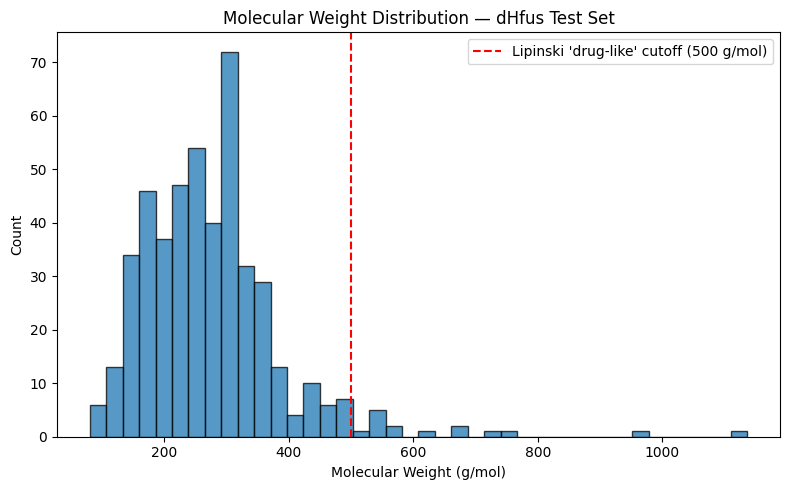

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(baseline_predictions["MW"], bins=40, edgecolor="black", alpha=0.75)
ax.axvline(500, color="red", linestyle="--", label="Lipinski 'drug-like' cutoff (500 g/mol)")
ax.set_xlabel("Molecular Weight (g/mol)")
ax.set_ylabel("Count")
ax.set_title("Molecular Weight Distribution — dHfus Test Set")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_MW_distribution.png", dpi=150)
plt.show()


             n  mw_range  mean_abs_error  median_abs_error  mean_rel_error
mw_bin                                                                    
Small MW   158    80-223        1.295504          0.963099      102.617723
Medium MW  156   224-302        1.322356          0.920059       24.775425
Large MW   151  302-1136        1.786977          1.279111       23.851810


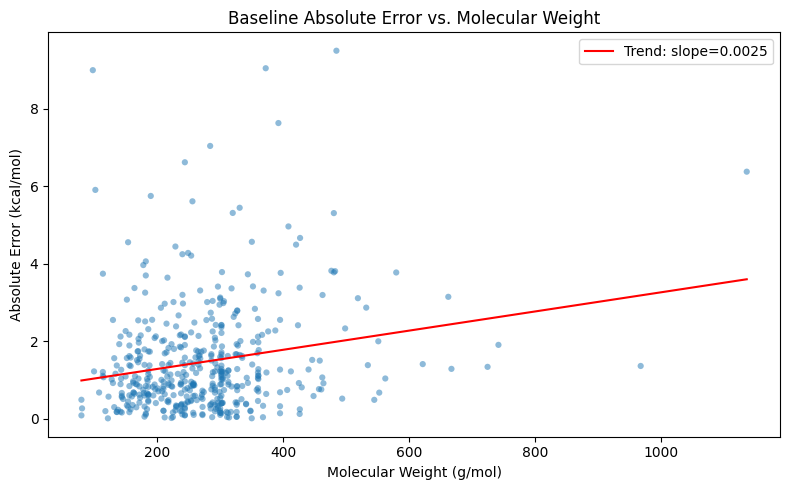

Correlation between MW and absolute error: 0.202


In [10]:
#BINS BASED ON TERTILES OF THE ACTUAL TEST-SET MW DISTRIBUTION, NOT ARBITRARY ROUND NUMBERS
mw_bins = baseline_predictions["MW"].quantile([0, 1/3, 2/3, 1]).values
mw_labels = ["Small MW", "Medium MW", "Large MW"]
baseline_predictions["mw_bin"] = pd.cut(baseline_predictions["MW"], bins=mw_bins, labels=mw_labels, include_lowest=True)

mw_error_table = baseline_predictions.groupby("mw_bin", observed=True).agg(
    n=("abs_error", "count"),
    mw_range=("MW", lambda x: f"{x.min():.0f}-{x.max():.0f}"),
    mean_abs_error=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"),
    mean_rel_error=("rel_error_pct", "mean"),
)
print(mw_error_table)

#SCATTER OF ERROR VS MW, CONTINUOUS TREND — MORE INFORMATIVE THAN BINNED BARS ALONE
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline_predictions["MW"], baseline_predictions["abs_error"], alpha=0.5, s=20, edgecolor="none")
slope, intercept = np.polyfit(baseline_predictions["MW"], baseline_predictions["abs_error"], 1)
x_line = np.array([baseline_predictions["MW"].min(), baseline_predictions["MW"].max()])
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=1.5, label=f"Trend: slope={slope:.4f}")
ax.set_xlabel("Molecular Weight (g/mol)")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Baseline Absolute Error vs. Molecular Weight")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_MW.png", dpi=150)
plt.show()

corr = np.corrcoef(baseline_predictions["MW"], baseline_predictions["abs_error"])[0, 1]
print(f"Correlation between MW and absolute error: {corr:.3f}")


In [11]:
#LOAD FULL DATASET FRESH (NOT JUST TEST SET) TO GET TRAIN-ELIGIBLE MOLECULES FOR SUBSET FILTERING
input_path = Path("RAW DATA") / "dHfus_DB.csv"
smiles_column = "smiles"
target_columns = ["dHfus [kcal/mol]"]

df_clean, all_data, mols = load_and_clean_data(input_path, smiles_column, target_columns)
df_clean["MW"] = df_clean[smiles_column].apply(lambda s: Descriptors.MolWt(Chem.MolFromSmiles(s)))

#DEFINE SMALL/LARGE SUBSETS BASED ON THE SAME TERTILE CUTOFFS AS THE POST-HOC ANALYSIS, FOR CONSISTENCY
mw_cutoffs = df_clean["MW"].quantile([1/3, 2/3]).values
small_mask = df_clean["MW"] <= mw_cutoffs[0]
large_mask = df_clean["MW"] >= mw_cutoffs[1]

print(f"Small MW subset: {small_mask.sum()} molecules (MW <= {mw_cutoffs[0]:.0f})")
print(f"Large MW subset: {large_mask.sum()} molecules (MW >= {mw_cutoffs[1]:.0f})")

small_indices = df_clean[small_mask].index.tolist()
large_indices = df_clean[large_mask].index.tolist()

small_data = [all_data[i] for i in small_indices]
small_mols = [mols[i] for i in small_indices]
large_data = [all_data[i] for i in large_indices]
large_mols = [mols[i] for i in large_indices]

mw_subset_results = {}

for subset_name, subset_data, subset_mols in [("small_MW", small_data, small_mols), ("large_MW", large_data, large_mols)]:
    subset_splits = build_splits(subset_data, subset_mols, split_types=("scaffold_balanced",))
    result = build_and_train_mpnn(
        subset_splits["scaffold_balanced"]["train"],
        subset_splits["scaffold_balanced"]["val"],
        subset_splits["scaffold_balanced"]["test"],
        dropout=0.4,
        run_name=f"dHfus_MW_{subset_name}",
    )
    preds = predict_test_set(result, run_name=f"dHfus_MW_{subset_name}")
    mw_subset_results[subset_name] = {"result": result, "predictions": preds}
    print(f"{subset_name}: MAE={preds['abs_error'].mean():.3f}, RMSE={np.sqrt((preds['abs_error']**2).mean()):.3f}")


comparison_rows = [{
    "Model": "Full baseline (all MW)",
    "MAE": baseline_predictions["abs_error"].mean(),
    "RMSE": np.sqrt((baseline_predictions["abs_error"] ** 2).mean()),
    "N_test": len(baseline_predictions),
}]
for subset_name, data_dict in mw_subset_results.items():
    p = data_dict["predictions"]
    comparison_rows.append({
        "Model": f"Trained on {subset_name} only",
        "MAE": p["abs_error"].mean(),
        "RMSE": np.sqrt((p["abs_error"] ** 2).mean()),
        "N_test": len(p),
    })

mw_comparison_df = pd.DataFrame(comparison_rows)
print(mw_comparison_df.to_string(index=False))
mw_comparison_df.to_csv("dHfus_MW_subset_comparison.csv", index=False)





[12:12:51] WARNING: not removing hydrogen atom without neighbors
[12:12:51] WARNING: not removing hydrogen atom without neighbors
[12:12:51] WARNING: not removing hydrogen atom without neighbors
[12:12:51] WARNING: not removing hydrogen atom without neighbors
[12:12:51] WARNING: not removing hydrogen atom without neighbors
[12:12:51] WARNING: not removing hydrogen atom without neighbors
[12:12:51] WARNING: not removing hydrogen atom without neighbors
[12:12:51] Unusual charge on atom 6 number of radical electrons set to zero


Loaded 5184 rows, dropped 527 with missing/invalid target, smiles, or stereo, 4657 remain


[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] Unusual charge on atom 6 number of radical electrons set to zero
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] WARNING: not removing hydrogen atom without neighbors
[12:12:52] Unu

Small MW subset: 1555 molecules (MW <= 176)
Large MW subset: 1553 molecules (MW >= 283)
scaffold_balanced: train=1245, val=155, test=155


c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\utilities\_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.
c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\loops\fit_loop.py:317: The number of training batches (20) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


┏━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name            ┃ Type               ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ message_passing │ BondMessagePassing │  227 K │ train │     0 │
│ 1 │ agg             │ MeanAggregation    │      0 │ train │     0 │
│ 2 │ bn              │ BatchNorm1d        │    600 │ train │     0 │
│ 3 │ predictor       │ RegressionFFN      │ 90.6 K │ train │     0 │
│ 4 │ X_d_transform   │ Identity           │      0 │ train │     0 │
│ 5 │ metrics         │ ModuleList         │      0 │ train │     0 │
└───┴─────────────────┴────────────────────┴────────┴───────┴───────┘

... (21 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│         test/mae          │    2.9360623359680176     │
│         test/rmse         │    3.9397826194763184     │
└───────────────────────────┴───────────────────────────┘

Output()

c:\Users\Jaco Olivier\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightning\pytorch\trainer\connectors\data_connector.py:434: The 'predict_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.


large_MW: MAE=2.936, RMSE=3.940
                   Model      MAE     RMSE  N_test
  Full baseline (all MW) 1.464109 2.014384     465
Trained on small_MW only 1.125453 1.993662     155
Trained on large_MW only 2.936062 3.939782     155


         HB_total  rotatable_bonds
count  465.000000       465.000000
mean     2.800000         2.686022
std      2.574075         4.886240
min      0.000000         0.000000
25%      0.000000         1.000000
50%      3.000000         2.000000
75%      4.000000         3.000000
max     19.000000        69.000000
                    n  mean_abs_error  median_abs_error
hb_bin                                                 
Low H-bonding     157        1.423280          1.009953
Medium H-bonding  209        1.416062          1.052957
High H-bonding     99        1.630291          1.220677


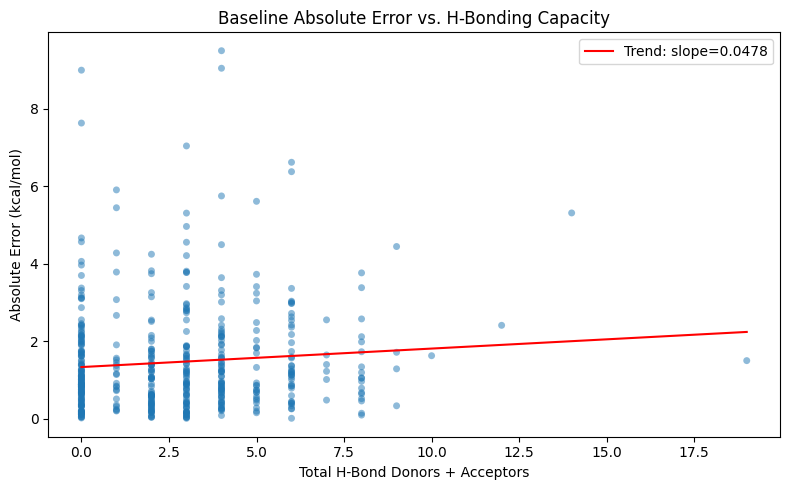

Correlation between H-bonding capacity and absolute error: 0.089
                        n  mean_abs_error  median_abs_error
rb_bin                                                     
Rigid                 222        1.362151          0.938464
Moderate flexibility  131        1.431628          1.179716
Highly flexible       112        1.704196          1.273169


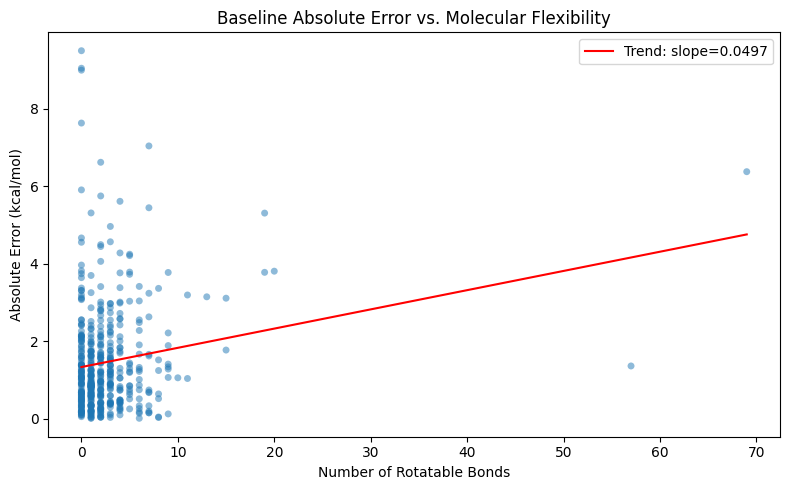

Correlation between rotatable bonds and absolute error: 0.175


In [12]:
from rdkit.Chem import Lipinski

#H-BONDING CAPACITY — SUM OF DONORS AND ACCEPTORS
baseline_predictions["HBD"] = baseline_predictions["smiles"].apply(lambda s: Lipinski.NumHDonors(Chem.MolFromSmiles(s)))
baseline_predictions["HBA"] = baseline_predictions["smiles"].apply(lambda s: Lipinski.NumHAcceptors(Chem.MolFromSmiles(s)))
baseline_predictions["HB_total"] = baseline_predictions["HBD"] + baseline_predictions["HBA"]

#ROTATABLE BONDS — CONFORMATIONAL FLEXIBILITY PROXY
baseline_predictions["rotatable_bonds"] = baseline_predictions["smiles"].apply(
    lambda s: Descriptors.NumRotatableBonds(Chem.MolFromSmiles(s))
)

print(baseline_predictions[["HB_total", "rotatable_bonds"]].describe())

#BIN BY H-BONDING CAPACITY (TERTILES OF ACTUAL DATA DISTRIBUTION)
hb_bins = baseline_predictions["HB_total"].quantile([0, 1/3, 2/3, 1]).unique()
if len(hb_bins) < 4:   #GUARDS AGAINST DUPLICATE BIN EDGES IF MANY MOLECULES SHARE THE SAME HB_total VALUE
    hb_bins = [baseline_predictions["HB_total"].min() - 0.5, 1.5, 3.5, baseline_predictions["HB_total"].max() + 0.5]
hb_labels = ["Low H-bonding", "Medium H-bonding", "High H-bonding"]
baseline_predictions["hb_bin"] = pd.cut(baseline_predictions["HB_total"], bins=hb_bins, labels=hb_labels, include_lowest=True)

hb_error_table = baseline_predictions.groupby("hb_bin", observed=True).agg(
    n=("abs_error", "count"),
    mean_abs_error=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"),
)
print(hb_error_table)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline_predictions["HB_total"], baseline_predictions["abs_error"], alpha=0.5, s=25, edgecolor="none")
slope, intercept = np.polyfit(baseline_predictions["HB_total"], baseline_predictions["abs_error"], 1)
x_line = np.array([baseline_predictions["HB_total"].min(), baseline_predictions["HB_total"].max()])
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=1.5, label=f"Trend: slope={slope:.4f}")
ax.set_xlabel("Total H-Bond Donors + Acceptors")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Baseline Absolute Error vs. H-Bonding Capacity")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_HB.png", dpi=150)
plt.show()

corr_hb = np.corrcoef(baseline_predictions["HB_total"], baseline_predictions["abs_error"])[0, 1]
print(f"Correlation between H-bonding capacity and absolute error: {corr_hb:.3f}")

rb_bins = baseline_predictions["rotatable_bonds"].quantile([0, 1/3, 2/3, 1]).unique()
if len(rb_bins) < 4:
    rb_bins = [baseline_predictions["rotatable_bonds"].min() - 0.5, 2.5, 6.5, baseline_predictions["rotatable_bonds"].max() + 0.5]
rb_labels = ["Rigid", "Moderate flexibility", "Highly flexible"]
baseline_predictions["rb_bin"] = pd.cut(baseline_predictions["rotatable_bonds"], bins=rb_bins, labels=rb_labels, include_lowest=True)

rb_error_table = baseline_predictions.groupby("rb_bin", observed=True).agg(
    n=("abs_error", "count"),
    mean_abs_error=("abs_error", "mean"),
    median_abs_error=("abs_error", "median"),
)
print(rb_error_table)

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(baseline_predictions["rotatable_bonds"], baseline_predictions["abs_error"], alpha=0.5, s=25, edgecolor="none")
slope, intercept = np.polyfit(baseline_predictions["rotatable_bonds"], baseline_predictions["abs_error"], 1)
x_line = np.array([baseline_predictions["rotatable_bonds"].min(), baseline_predictions["rotatable_bonds"].max()])
ax.plot(x_line, slope * x_line + intercept, color="red", linewidth=1.5, label=f"Trend: slope={slope:.4f}")
ax.set_xlabel("Number of Rotatable Bonds")
ax.set_ylabel("Absolute Error (kcal/mol)")
ax.set_title("Baseline Absolute Error vs. Molecular Flexibility")
ax.legend()
plt.tight_layout()
plt.savefig("plots_dHfus_error_vs_rotatable.png", dpi=150)
plt.show()

corr_rb = np.corrcoef(baseline_predictions["rotatable_bonds"], baseline_predictions["abs_error"])[0, 1]
print(f"Correlation between rotatable bonds and absolute error: {corr_rb:.3f}")